In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Dataset paths
train_path = "../data/NEU-DET/train/images"
val_path = "../data/NEU-DET/validation/images"

print("Train Path Exists:", os.path.exists(train_path))
print("Validation Path Exists:", os.path.exists(val_path))

Train Path Exists: True
Validation Path Exists: True


In [2]:
#import sys
#print(sys.executable)

In [3]:
import os

classes = os.listdir("../data/NEU-DET/train/images")
print(classes)

['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


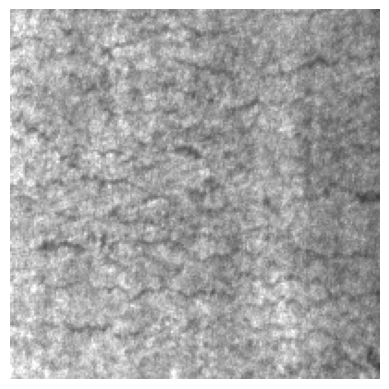

In [4]:
from PIL import Image
import matplotlib.pyplot as plt

img_path = "../data/NEU-DET/train/images/crazing/" + os.listdir("../data/NEU-DET/train/images/crazing")[0]

img = Image.open(img_path)

plt.imshow(img)
plt.axis("off")
plt.show()

In [5]:
import os

classes = os.listdir("../data/NEU-DET/train/images")
print(classes)

['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


In [6]:
import os

train_dir = "../data/NEU-DET/train/images"

for cls in os.listdir(train_dir):
    cls_path = os.path.join(train_dir, cls)
    print(f"{cls}: {len(os.listdir(cls_path))} images")

crazing: 240 images
inclusion: 240 images
patches: 240 images
pitted_surface: 240 images
rolled-in_scale: 240 images
scratches: 240 images


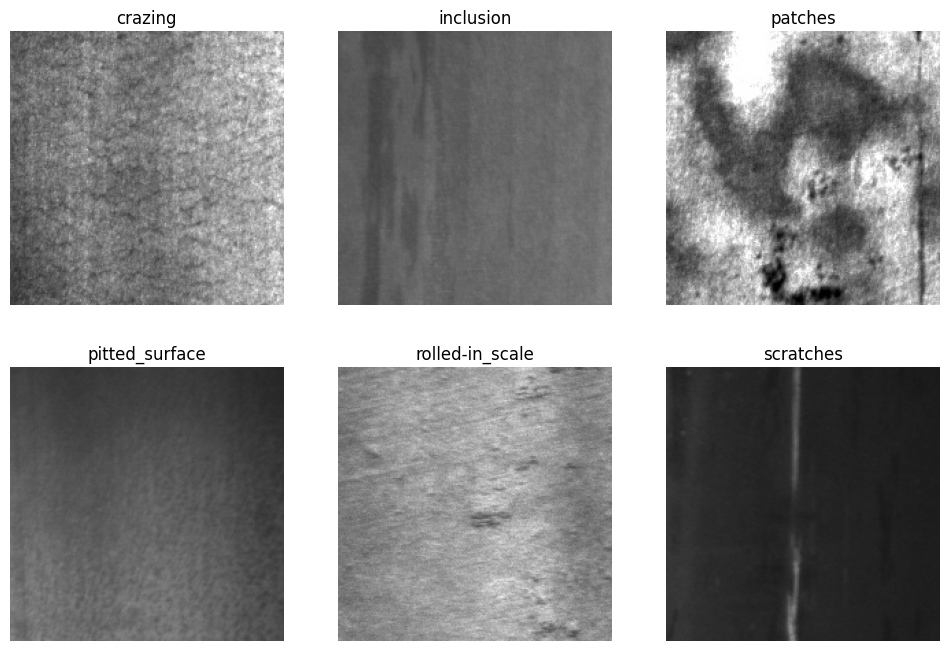

In [7]:
from PIL import Image
import matplotlib.pyplot as plt
import random
import os

classes = os.listdir("../data/NEU-DET/train/images")

plt.figure(figsize=(12,8))

for i, cls in enumerate(classes):
    img_name = random.choice(os.listdir(f"../data/NEU-DET/train/images/{cls}"))
    img_path = f"../data/NEU-DET/train/images/{cls}/{img_name}"

    img = Image.open(img_path)

    plt.subplot(2,3,i+1)
    plt.imshow(img)
    plt.title(cls)
    plt.axis("off")

plt.show()

In [8]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [9]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(
    rescale=1./255
)

In [10]:
train_data = train_datagen.flow_from_directory(
    "../data/NEU-DET/train/images",
    target_size=(224,224),
    batch_size=32,
    class_mode="categorical"
)

Found 1440 images belonging to 6 classes.


In [11]:
val_data = val_datagen.flow_from_directory(
    "../data/NEU-DET/validation/images",
    target_size=(224,224),
    batch_size=32,
    class_mode="categorical"
)

Found 360 images belonging to 6 classes.


In [12]:
print(train_data.class_indices)

{'crazing': 0, 'inclusion': 1, 'patches': 2, 'pitted_surface': 3, 'rolled-in_scale': 4, 'scratches': 5}


In [13]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(224,224,3)),
    MaxPooling2D(pool_size=(2,2)),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(pool_size=(2,2)),

    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(pool_size=(2,2)),

    Flatten(),

    Dense(128, activation='relu'),
    Dropout(0.5),

    Dense(6, activation='softmax')
])

model.summary()

c:\Users\sanik\OneDrive\Desktop\Manufacturing_Defect_Detection\venv\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,734 (42.61 MB)

 Trainable params: 11,169,734 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [15]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10
)

Epoch 1/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 92s 2s/step - accuracy: 0.2208 - loss: 1.8936 - val_accuracy: 0.4139 - val_loss: 1.6299
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 47s 1s/step - accuracy: 0.5215 - loss: 1.2466 - val_accuracy: 0.4750 - val_loss: 1.3830
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 51s 1s/step - accuracy: 0.6944 - loss: 0.8385 - val_accuracy: 0.7444 - val_loss: 0.7438
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 60s 1s/step - accuracy: 0.7917 - loss: 0.6261 - val_accuracy: 0.3278 - val_loss: 1.7163
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 60s 1s/step - accuracy: 0.8146 - loss: 0.5692 - val_accuracy: 0.8806 - val_loss: 0.4386
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 59s 1s/step - accuracy: 0.8062 - loss: 0.5574 - val_accuracy: 0.8472 - val_loss: 0.5570
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 79s 2s/step - accuracy: 0.8292 - loss: 0.5339 - val_accuracy: 0.6139 - val_loss: 1.1609
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 86s 2s/step - accuracy: 0.8847 - loss: 0.3856 - val_accuracy: 0.6167 - val_loss:

In [16]:
model.save("../models/manufacturing_defect_model.keras")
print("Model saved successfully!")

Model saved successfully!


In [17]:
loss, accuracy = model.evaluate(val_data)

print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy)

12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 245ms/step - accuracy: 0.8333 - loss: 0.4522
Validation Loss: 0.45224398374557495
Validation Accuracy: 0.8333333134651184


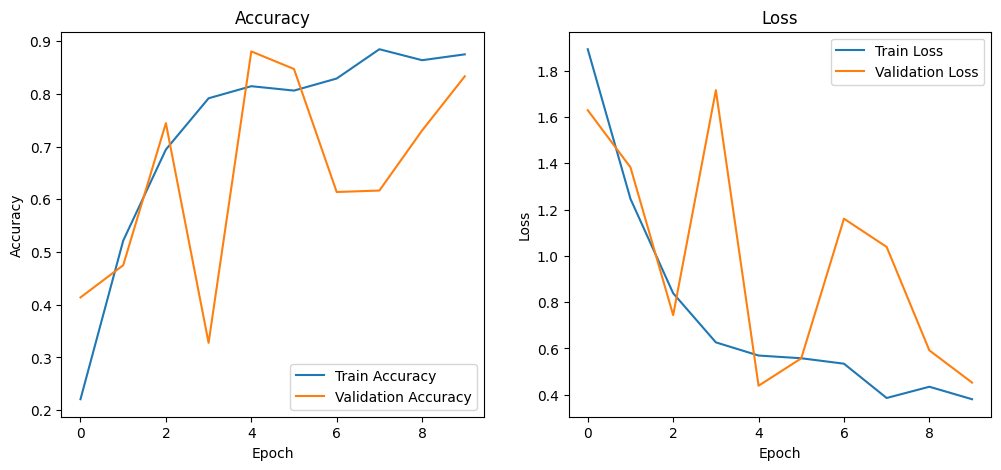

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

# Accuracy
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

In [19]:
import numpy as np
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt

In [20]:
model = load_model("../models/manufacturing_defect_model.keras")

In [21]:
img_path = r"C:\Users\sanik\Downloads\ChatGPT Image Aug 6, 2026, 03_06_06 PM.png"

In [22]:
img = image.load_img(img_path, target_size=(224,224))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = img_array / 255.0

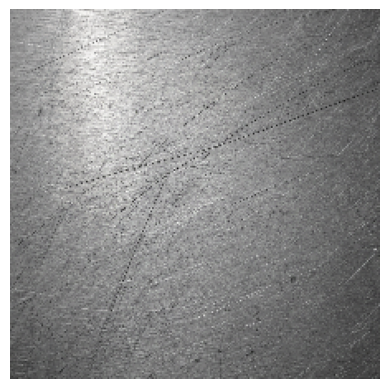

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 312ms/step
Predicted Defect: crazing
Confidence: 0.9998808


In [23]:
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt

# Load Image
img = image.load_img(img_path, target_size=(224,224))

# Display Image
plt.imshow(img)
plt.axis("off")
plt.show()

# Convert Image
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = img_array / 255.0

# Predict
prediction = model.predict(img_array)

# Class Names
class_names = ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']

predicted_class = class_names[np.argmax(prediction)]

print("Predicted Defect:", predicted_class)
print("Confidence:", np.max(prediction))

In [24]:
from sklearn.metrics import confusion_matrix, classification_report


In [25]:
y_true = val_data.classes

y_pred = model.predict(val_data)
y_pred = np.argmax(y_pred, axis=1)

print(classification_report(y_true, y_pred))

12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 270ms/step
              precision    recall  f1-score   support

           0       0.22      0.23      0.23        60
           1       0.11      0.08      0.09        60
           2       0.18      0.20      0.19        60
           3       0.11      0.10      0.11        60
           4       0.17      0.22      0.19        60
           5       0.13      0.12      0.12        60

    accuracy                           0.16       360
   macro avg       0.15      0.16      0.16       360
weighted avg       0.15      0.16      0.16       360



In [26]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [27]:
from sklearn.metrics import confusion_matrix

In [28]:
classification_report

<function sklearn.metrics._classification.classification_report(y_true, y_pred, *, labels=None, target_names=None, sample_weight=None, digits=2, output_dict=False, zero_division='warn')>

In [29]:
import seaborn as sns
import seaborn as sns
import numpy as np

In [30]:
val_data.reset()

predictions = model.predict(val_data)

y_pred = np.argmax(predictions, axis=1)

y_true = val_data.classes

12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 252ms/step


In [31]:
cm = confusion_matrix(y_true, y_pred)

print(cm)

[[12  6 11 11 10 10]
 [10 14 13  7 13  3]
 [ 9  6 13 12 12  8]
 [13  7 10  9 12  9]
 [ 9  5 10  6 17 13]
 [10  8 10  8 12 12]]


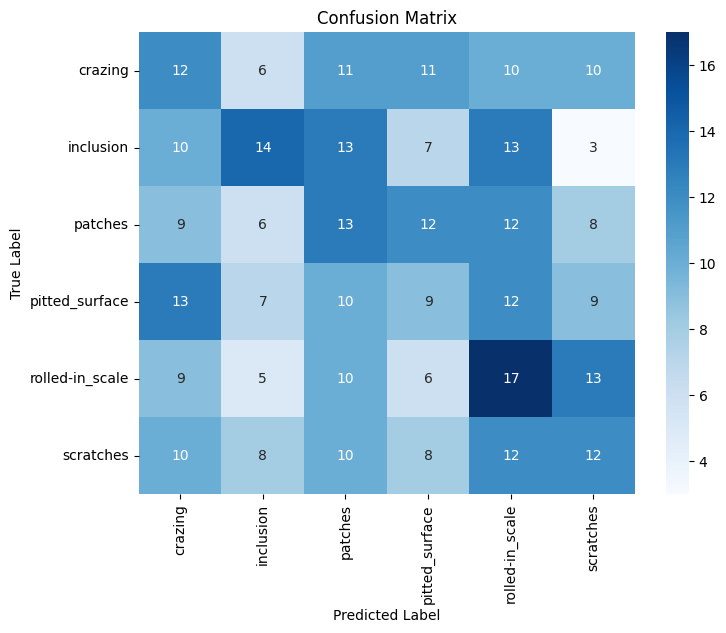

In [32]:
plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=train_data.class_indices.keys(),
    yticklabels=train_data.class_indices.keys()
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

In [33]:
print(val_data.shuffle)

True


In [34]:
val_data = val_datagen.flow_from_directory(
    "../data/NEU-DET/validation/images",
    target_size=(224,224),
    batch_size=32,
    class_mode="categorical",
    shuffle=False
)

Found 360 images belonging to 6 classes.


In [35]:
val_data.reset()

predictions = model.predict(val_data)

y_pred = np.argmax(predictions, axis=1)

y_true = val_data.classes

12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 241ms/step


In [36]:
cm = confusion_matrix(y_true, y_pred)

In [37]:
print(val_data.shuffle)

False


In [38]:
print(classification_report(
    y_true,
    y_pred,
    target_names=list(train_data.class_indices.keys())
))

                 precision    recall  f1-score   support

        crazing       0.92      0.97      0.94        60
      inclusion       0.87      0.67      0.75        60
        patches       0.88      0.98      0.93        60
 pitted_surface       0.62      0.55      0.58        60
rolled-in_scale       0.79      1.00      0.88        60
      scratches       0.91      0.83      0.87        60

       accuracy                           0.83       360
      macro avg       0.83      0.83      0.83       360
   weighted avg       0.83      0.83      0.83       360



In [39]:
val_data.reset()

predictions = model.predict(val_data)

y_pred = np.argmax(predictions, axis=1)

y_true = val_data.classes

12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 244ms/step


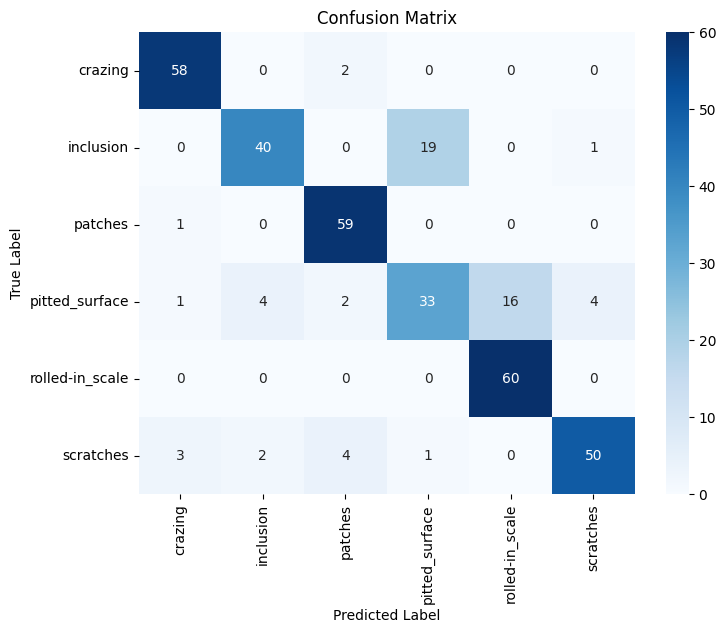

In [40]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=list(train_data.class_indices.keys()),
    yticklabels=list(train_data.class_indices.keys())
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

In [41]:
print(classification_report(
    y_true,
    y_pred,
    target_names=list(train_data.class_indices.keys())
))

                 precision    recall  f1-score   support

        crazing       0.92      0.97      0.94        60
      inclusion       0.87      0.67      0.75        60
        patches       0.88      0.98      0.93        60
 pitted_surface       0.62      0.55      0.58        60
rolled-in_scale       0.79      1.00      0.88        60
      scratches       0.91      0.83      0.87        60

       accuracy                           0.83       360
      macro avg       0.83      0.83      0.83       360
   weighted avg       0.83      0.83      0.83       360



12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 258ms/step


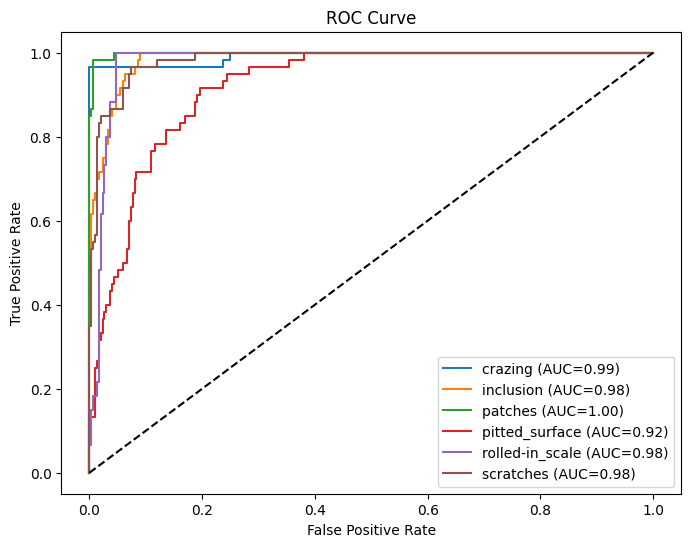

In [42]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# True labels
y_true = val_data.classes

# Predicted probabilities
y_prob = model.predict(val_data)

# Convert labels to binary
n_classes = len(train_data.class_indices)
y_true_bin = label_binarize(y_true, classes=range(n_classes))

plt.figure(figsize=(8,6))

for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_prob[:, i])
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f'{list(train_data.class_indices.keys())[i]} (AUC={roc_auc:.2f})')

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()

plt.show()

In [43]:
print("="*50)
print("MANUFACTURING DEFECT DETECTION MODEL REPORT")
print("="*50)

print(f"Training Accuracy      : {history.history['accuracy'][-1]:.2f}")
print(f"Validation Accuracy    : {history.history['val_accuracy'][-1]:.2f}")
print(f"Training Loss          : {history.history['loss'][-1]:.2f}")
print(f"Validation Loss        : {history.history['val_loss'][-1]:.2f}")

print("="*50)

MANUFACTURING DEFECT DETECTION MODEL REPORT
Training Accuracy      : 0.88
Validation Accuracy    : 0.83
Training Loss          : 0.38
Validation Loss        : 0.45


In [44]:
img_path = r"C:\Users\sanik\Downloads\ChatGPT Image Aug 6, 2026, 03_06_06 PM.png"

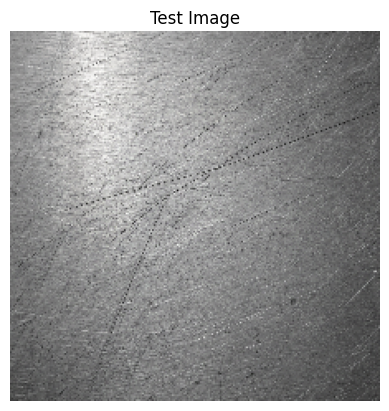

In [45]:
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt

img = image.load_img(img_path, target_size=(224, 224))

plt.imshow(img)
plt.title("Test Image")
plt.axis("off")
plt.show()

img_array = image.img_to_array(img)
img_array = img_array / 255.0
img_array = np.expand_dims(img_array, axis=0)

In [46]:
prediction = model.predict(img_array)

predicted_index = np.argmax(prediction)

class_names = list(train_data.class_indices.keys())

predicted_class = class_names[predicted_index]

confidence = np.max(prediction) * 100

print("Predicted Class :", predicted_class)
print(f"Confidence : {confidence:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
Predicted Class : crazing
Confidence : 99.99%


In [47]:
prediction = model.predict(img_array)

class_names = list(train_data.class_indices.keys())

top3_idx = np.argsort(prediction[0])[-3:][::-1]

predicted_class = class_names[top3_idx[0]]
confidence = prediction[0][top3_idx[0]] * 100

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step


In [48]:
print("="*60)
print("      MANUFACTURING DEFECT DETECTION SYSTEM")
print("="*60)

print("\n🔍 TOP 3 PREDICTIONS\n")

for rank, i in enumerate(top3_idx, start=1):
    print(f"{rank}. {class_names[i]:20} {prediction[0][i]*100:.2f}%")

print("\n" + "="*60)

print("🏆 FINAL RESULT\n")

print(f"✅ Defect Detected : {predicted_class.upper()}")

print(f"🎯 Confidence      : {confidence:.2f}%")

print("="*60)

      MANUFACTURING DEFECT DETECTION SYSTEM

🔍 TOP 3 PREDICTIONS

1. crazing              99.99%
2. patches              0.01%
3. rolled-in_scale      0.00%

🏆 FINAL RESULT

✅ Defect Detected : CRAZING
🎯 Confidence      : 99.99%


In [49]:
import tensorflow as tf
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [50]:
for layer in model.layers:
    print(layer.name)

conv2d
max_pooling2d
conv2d_1
max_pooling2d_1
conv2d_2
max_pooling2d_2
flatten
dense
dropout
dense_1


In [51]:
last_conv_layer = model.get_layer("conv2d_2")

grad_model = tf.keras.models.Model(
    inputs=model.inputs,
    outputs=[last_conv_layer.output, model.output]
)

AttributeError: The layer sequential has never been called and thus has no defined output.

In [ ]:
print(model.inputs)
print(model.outputs)

[<KerasTensor shape=(None, 224, 224, 3), dtype=float32, sparse=False, ragged=False, name=input_layer>]
[<KerasTensor shape=(None, 6), dtype=float32, sparse=False, ragged=False, name=keras_tensor_71>]


In [ ]:
_ = model(img_array)

In [ ]:
last_conv_layer = model.get_layer("conv2d_2")

grad_model = tf.keras.models.Model(
    inputs=model.inputs,
    outputs=[
        last_conv_layer.output,
        model.outputs[0]
    ]
)

print("Grad-CAM Model Created Successfully!")

Grad-CAM Model Created Successfully!


In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Resize heatmap to image size
heatmap = cv2.resize(heatmap, (224, 224))

# Convert heatmap to color
heatmap = np.uint8(255 * heatmap)
heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

# Original image
original = img_array[0] * 255
original = original.astype(np.uint8)

# Overlay
superimposed = cv2.addWeighted(original, 0.6, heatmap, 0.4, 0)

# Show
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(cv2.cvtColor(superimposed, cv2.COLOR_BGR2RGB))
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.show()

NameError: name 'heatmap' is not defined

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,509,204 (127.83 MB)

 Trainable params: 11,169,734 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 22,339,470 (85.22 MB)

In [ ]:
for i, layer in enumerate(model.layers):
    print(i, layer.name, layer.output_shape if hasattr(layer, "output_shape") else "")

0 conv2d 
1 max_pooling2d 
2 conv2d_1 
3 max_pooling2d_1 
4 conv2d_2 
5 max_pooling2d_2 
6 flatten 
7 dense 
8 dropout 
9 dense_1 


In [ ]:
_ = model(img_array)

In [ ]:
last_conv_layer = model.get_layer("conv2d_2")

grad_model = tf.keras.models.Model(
    inputs=model.input,
    outputs=[
        last_conv_layer.output,
        model.layers[-1].output
    ]
)

print("Grad Model Ready")

AttributeError: The layer sequential has never been called and thus has no defined input.

In [ ]:
print(type(model))
print(model.built)
print(model.inputs)

<class 'keras.src.models.sequential.Sequential'>
True
[<KerasTensor shape=(None, 224, 224, 3), dtype=float32, sparse=False, ragged=False, name=input_layer>]


In [ ]:
model(img_array, training=False)
print(model.built)

True


In [ ]:
import tensorflow as tf

# Create a fresh functional model
grad_input = tf.keras.Input(shape=(224, 224, 3))

x = grad_input

# Pass through the original model layer-by-layer
for layer in model.layers:
    x = layer(x)

# Model that gives final prediction
full_model = tf.keras.Model(
    inputs=grad_input,
    outputs=x
)

print("Fresh model created!")

Grad Model Ready


In [ ]:
with tf.GradientTape() as tape:

    conv_outputs, predictions = grad_model(
        img_array,
        training=False
    )

    pred_index = tf.argmax(predictions[0])
    class_channel = predictions[:, pred_index]

grads = tape.gradient(class_channel, conv_outputs)

print("Gradient:", grads is not None)

if grads is None:
    print("❌ Gradient still not connected")
else:
    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    max_value = tf.reduce_max(heatmap)

    if max_value != 0:
        heatmap = heatmap / max_value

    heatmap = heatmap.numpy()

    print("✅ Heatmap Created Successfully!")

c:\Users\sanik\OneDrive\Desktop\Manufacturing_Defect_Detection\venv\lib\site-packages\keras\src\models\functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


ValueError: Attempt to convert a value (None) with an unsupported type (<class 'NoneType'>) to a Tensor.